# 13 · Reverse osmosis and ultrafiltration

Pressure-driven membranes separate liquids by size and by solution-diffusion: reverse osmosis desalts
seawater against an osmotic pressure of tens of bar, nanofiltration softens, ultrafiltration retains proteins
and colloids, microfiltration clarifies. This notebook computes osmotic pressures, water and salt fluxes,
rejection and recovery for an RO plant, the gel-polarisation limit of ultrafiltration, and a countercurrent
dialyser.

**What you will learn**
- compute osmotic pressures and the minimum work of desalination
- solve the coupled water and salt fluxes of RO
- estimate concentration polarisation and the gel-polarisation limit of UF
- design a countercurrent dialyser

**Before you start:** notebook 12  ·  **Time:** about 60 min

In [1]:
try:                      # on Google Colab (or anywhere engsep is missing): install it from GitHub
    import engsep
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "git+https://github.com/ktwyw/engsep"], check=True)
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from engsep import membranes as mb
plt.rcParams.update({"figure.figsize": (7, 4), "figure.dpi": 90, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})

import inspect
from IPython.display import Code

def show_source(obj):
    """Display the source code of a library function or class."""
    return Code(inspect.getsource(obj), language="python")

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## Osmotic pressure: the price of desalination

In [2]:
T = 298.15
for name, c_salt in (("brackish water (2 g/L NaCl)", 2 / 58.44), ("seawater (35 g/L)", 35 / 58.44), ("brine at 50 % recovery (70 g/L)", 70 / 58.44)):
    pi = mb.osmotic_pressure(2 * c_salt, T)
    print(f"{name:<32}: {c_salt:.3f} mol/L -> osmotic pressure {pi/1e5:.1f} bar (ideal van 't Hoff)")
print("the minimum work of desalination is the osmotic pressure times the volume: about 0.8 kWh/m3 for seawater at 50 % recovery; real plants use 3-4")

brackish water (2 g/L NaCl)     : 0.034 mol/L -> osmotic pressure 1.7 bar (ideal van 't Hoff)
seawater (35 g/L)               : 0.599 mol/L -> osmotic pressure 29.7 bar (ideal van 't Hoff)
brine at 50 % recovery (70 g/L) : 1.198 mol/L -> osmotic pressure 59.4 bar (ideal van 't Hoff)
the minimum work of desalination is the osmotic pressure times the volume: about 0.8 kWh/m3 for seawater at 50 % recovery; real plants use 3-4


Van 't Hoff's law - osmotic pressure like an ideal-gas pressure of the dissolved ions - puts seawater near
30 bar and its concentrate at 50 % recovery near 60; the applied pressure must exceed the *concentrate's*
osmotic pressure at the membrane, which is why seawater RO runs at 55-70 bar and why recovery is capped.

## Water and salt fluxes, rejection and recovery

In [3]:
A_w, B_s = 3e-12, 2e-8                                              # water permeability m/(s Pa), salt permeability m/s (typical seawater membrane)
c_feed = 35 / 58.44
rows = []
for dP_bar in (40, 50, 60, 70, 80):
    ro = mb.ro_permeate_concentration(A_w, B_s, dP_bar * 1e5, c_feed, T)
    rows.append((dP_bar, ro["J_w"] * 3600 * 1000, ro["c_permeate"] * 58.44 * 1000, ro["rejection"], mb.ro_recovery(c_feed, dP_bar * 1e5, T)))
print(pd.DataFrame(rows, columns=["dP (bar)", "water flux (L/(m2 h))", "permeate (mg/L NaCl)", "rejection", "max recovery"]).round(3).to_string(index=False))

 dP (bar)  water flux (L/(m2 h))  permeate (mg/L NaCl)  rejection  max recovery
       40                 11.334               220.940      0.994         0.258
       50                 22.036               113.987      0.997         0.406
       60                 32.802                76.657      0.998         0.505
       70                 43.584                57.724      0.998         0.576
       80                 54.374                46.285      0.999         0.629


Water flux grows with the net driving pressure ($\Delta P - \Delta\pi$) while salt flux depends only on the
concentration difference, so raising the pressure dilutes the salt in more water: rejection improves with
pressure. The permeate meets the 500 mg/L drinking-water limit above 50 bar; the maximum recovery - where the
concentrate's osmotic pressure catches the applied pressure - sets the plant's water yield.

## Concentration polarisation

In [4]:
J_w = mb.ro_permeate_concentration(A_w, B_s, 60e5, c_feed, T)["J_w"]
for k in (2e-5, 5e-5, 1e-4):
    cp = mb.concentration_polarisation(J_w, k)
    pi_wall = mb.osmotic_pressure(2 * c_feed * cp, T)
    print(f"mass-transfer coefficient {k:.0e} m/s: wall concentration {cp:.2f} x bulk -> osmotic pressure at the wall {pi_wall/1e5:.1f} bar instead of {mb.osmotic_pressure(2*c_feed, T)/1e5:.1f}")

mass-transfer coefficient 2e-05 m/s: wall concentration 1.58 x bulk -> osmotic pressure at the wall 46.8 bar instead of 29.7
mass-transfer coefficient 5e-05 m/s: wall concentration 1.20 x bulk -> osmotic pressure at the wall 35.6 bar instead of 29.7
mass-transfer coefficient 1e-04 m/s: wall concentration 1.10 x bulk -> osmotic pressure at the wall 32.5 bar instead of 29.7


Rejected salt piles up at the membrane surface until back-diffusion balances the convective flux: the wall
concentration exceeds the bulk by the factor $e^{J/k}$, raising the osmotic pressure the membrane sees and
the salt passage. Cross-flow velocity and spacers keep $k$ high; polarisation is why RO modules are
thin channels with turbulence promoters, and it is worse in ultrafiltration.

## Ultrafiltration: the gel layer

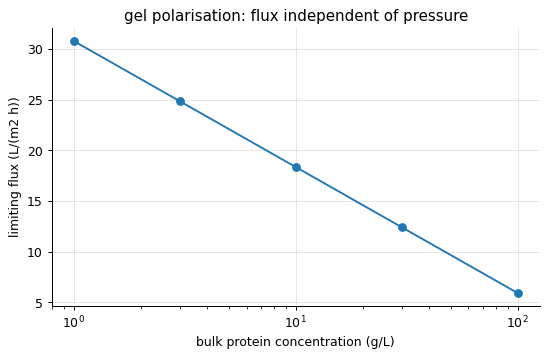

flux at 10 g/L: 18.4 L/(m2 h); it falls to zero as the bulk approaches the gel concentration


In [5]:
c_gel, k_uf = 300.0, 1.5e-6                                          # g/L (protein gel), m/s
cs = np.array([1, 3, 10, 30, 100.0])
J = mb.uf_limiting_flux(k_uf, c_gel, cs)
plt.semilogx(cs, J * 3600 * 1000, "o-"); plt.xlabel("bulk protein concentration (g/L)"); plt.ylabel("limiting flux (L/(m2 h))"); plt.title("gel polarisation: flux independent of pressure"); plt.show()
print("flux at 10 g/L:", round(float(J[2] * 3600 * 1000), 1), "L/(m2 h); it falls to zero as the bulk approaches the gel concentration")

Ultrafiltration of macromolecules polarises so strongly that a gel forms at the wall; beyond that point
more pressure only thickens the gel and the flux is set by mass transfer alone, $J = k\ln(c_{gel}/c_b)$. The
flux falls logarithmically as the retentate concentrates - which is why protein concentration by UF slows
towards the end and why diafiltration (adding water) is used to wash out small solutes.

## Dialysis

In [6]:
for area in (1.0, 2.0, 4.0):
    dz = mb.dialysis_countercurrent(P_m=1e-5, area=area, Q1=5e-6, Q2=1e-5, c1_in=1.0)
    print(f"membrane area {area} m2: NTU = {dz['NTU']:.1f}, removal of the small solute {dz['removal']:.1%}")

membrane area 1.0 m2: NTU = 2.0, removal of the small solute 77.5%
membrane area 2.0 m2: NTU = 4.0, removal of the small solute 92.7%
membrane area 4.0 m2: NTU = 8.0, removal of the small solute 99.1%


Dialysis needs no pressure: solutes diffuse down their concentration gradients across a membrane that
retains the large ones. A countercurrent dialyser is a heat exchanger in disguise - NTU, effectiveness and a
flow-ratio - and the haemodialyser that keeps a kidney patient alive is designed with exactly these two
lines of arithmetic.

## Inside the algorithm: van 't Hoff

In [7]:
from engsep.constants import R
print("by hand:", 2 * (35 / 58.44) * 1000 * R * 298.15 / 1e5, "bar; library:", mb.osmotic_pressure(2 * 35 / 58.44, 298.15) / 1e5)

by hand: 29.69318823904329 bar; library: 29.69318823904329


## Exercises
1. A brackish-water plant (2 g/L) runs at 15 bar with 75 % recovery. Compute the concentrate's osmotic pressure and check that the pressure suffices; then find the permeate concentration at the feed end and at the concentrate end of the module and their flow-weighted average.
2. Energy: compute the pumping energy per m3 of permeate for seawater at 60 bar and 45 % recovery with and without an energy-recovery device that returns 95 % of the concentrate's pressure energy. Compare with the thermodynamic minimum.
3. **Implement it yourself:** iterate the RO permeate concentration yourself (start with c_p = 0, compute Delta pi, J_w, J_s, update c_p) and reproduce `membranes.ro_permeate_concentration` at 60 bar.